Import and set up data

In [3]:
!pip install pandas seaborn matplotlib

  Using cached pandas-3.1.0-cp312-cp312-win_amd64.whl.metadata (18 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 80.3/80.3 kB 4.4 MB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     -------------------------------------- 139.8/139.8 kB 4.2 MB/s eta 0:00:00
Using cached pandas-3.1.0-cp312-cp312-win_amd64.whl (10.7 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 32.8 MB/s eta 0:00:01
   ------ --------------------------------- 1.6/9.3 MB 20.7 MB/s eta 0:00:01
   ------------- -------------------------- 3.1/9.3 MB 24.6 MB/s eta 0:00:01
   ----------------------- ---------------- 5.5/9.3 MB 31.9 MB/s eta 0:00:01
  


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# install py -m pip install pandas seaborn matplotlib
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.ticker as tic

sns.set_theme(style="whitegrid")

df = pd.read_csv("../Data/transformed_study_data.csv")

Matplotlib is building the font cache; this may take a moment.


Exploratory visualization #1

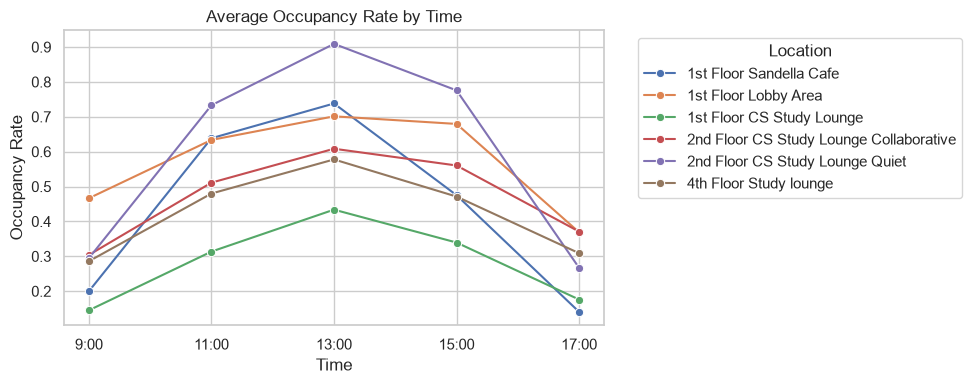

In [5]:
occupancy_time = (
    df.groupby(["time", "location"])["occupancy_rate"]
      .mean()
      .reset_index()
)

# Time ordering
time_order = ["9:00", "11:00", "13:00", "15:00", "17:00"]
occupancy_time["time"] = pd.Categorical(
    occupancy_time["time"],
    categories=time_order,
    ordered=True
)

# Location ordering
location_order = [
    "1st Floor Sandella Cafe",
    "1st Floor Lobby Area",
    "1st Floor CS Study Lounge",
    "2nd Floor CS Study Lounge Collaborative",
    "2nd Floor CS Study Lounge Quiet",
    "4th Floor Study lounge"
]
occupancy_time["location"] = pd.Categorical(
    occupancy_time["location"],
    categories=location_order,
    ordered=True
)

# Sort by time and location
occupancy_time = occupancy_time.sort_values(["time", "location"])

# Plot
plt.figure(figsize=(10, 4))
sns.lineplot(
    data=occupancy_time,
    x="time",
    y="occupancy_rate",
    hue="location",
    marker="o"
)
plt.title("Average Occupancy Rate by Time")
plt.xlabel("Time")
plt.ylabel("Occupancy Rate")

# Move legend outside plot
plt.legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Exploratory Visualization #2

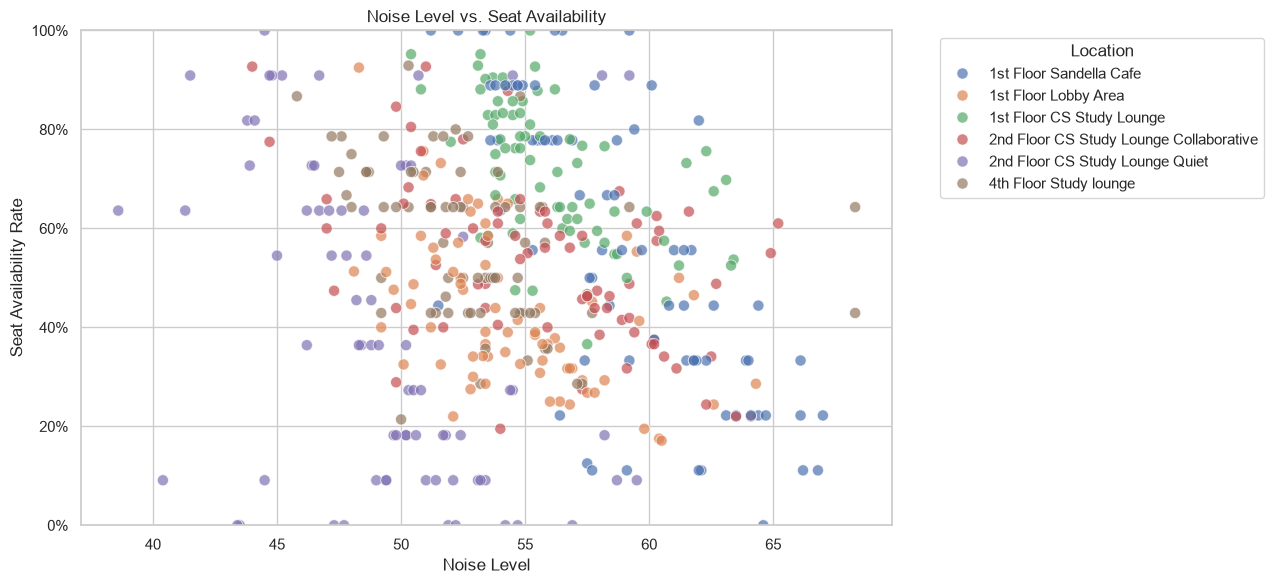

In [9]:
# compare noise level with seat availability

# Set the order of study space locations
location_order = [
    "1st Floor Sandella Cafe",
    "1st Floor Lobby Area",
    "1st Floor CS Study Lounge",
    "2nd Floor CS Study Lounge Collaborative",
    "2nd Floor CS Study Lounge Quiet",
    "4th Floor Study lounge"
]

# Set the location order in the dataset
df["location"] = pd.Categorical(
    df["location"],
    categories=location_order,
    ordered=True
)

# Increased figure size to give the plot and legend more room
plt.figure(figsize=(13, 6))

# scatterplot
sns.scatterplot(
    data=df,
    x="noise_level",
    y="availability_rate",
    hue="location",
    hue_order=location_order,
    alpha=0.7,
    s=65
)

plt.title("Noise Level vs. Seat Availability")
plt.xlabel("Noise Level")
plt.ylabel("Seat Availability Rate")

# current axes; set tick labels to percents; vertical axis limits 0 to 1
plt.gca().yaxis.set_major_formatter(
    tic.PercentFormatter(1.0)
)
plt.ylim(0, 1)

# Move legend outside the plot to prevent clipping
plt.legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()